# 👄 Mouth State — MobileNetV2 + Fine-tuning (Synapse)

**الهدف:** نفس مهمة مودل الفم v2 (طبيعي 0 / تثاؤب 1)، بس بـ **Transfer Learning**: MobileNetV2 متدرب على ImageNet + **Fine-tuning**.

**ليش ممكن يساعد هون أكثر من العين؟**
- صور الفم **ملونة** وقريبة من صور ImageNet العادية (بالعين كانت صور Infrared رمادية ← domain gap كبير).
- داتا الفم **صغيرة** (5,398 صورة) ← المعرفة المسبقة بتفيد أكثر لما الداتا قليلة.
- حجم 96×96 هو **حجم أصلي** مدعوم بأوزان MobileNetV2 ← ما في تكبير وضبابية زي العين.

| المرحلة | شو بنعمل | الـ LR |
|---|---|---|
| **1) Feature extraction** | نجمّد MobileNetV2 كامل وندرب الـ head بس | `1e-3` |
| **2) Fine-tuning** | نفك تجميد آخر 54 طبقة (ما عدا BatchNorm) | `1e-5` |

## 1) تجهيز البيئة
نفس الـ loader والـ splits تبع منار ← المقارنة مع v2 عادلة.

In [1]:
import os, sys, json, glob
if not os.path.exists("Synapse"):
    !git clone -q https://github.com/ManarAbu-Irsheid/Synapse.git
sys.path.insert(0, "Synapse/data_pipeline")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, precision_recall_fscore_support)
from mouth_dataset import make_mouth_dataset      # loader تبع Member 1

tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2) الإعدادات

In [2]:
OUT          = "/kaggle/working/mouth_mobilenetv2"
SPLITS_OUT   = "/kaggle/working/mouth_splits"
IMG_SIZE     = 96
BATCH        = 64
LR_HEAD, EPOCHS_HEAD = 1e-3, 10
LR_FT,   EPOCHS_FT   = 1e-5, 15
FINE_TUNE_AT = 100
CLASS_NAMES  = ["no_yawn", "yawn"]
os.makedirs(OUT, exist_ok=True); os.makedirs(SPLITS_OUT, exist_ok=True)

## 3) الداتا
نفس v2: إيجاد مجلد `nitymed_out` لحاله، تصليح المسارات، وخلط الـ train كامل.

In [3]:
found = glob.glob("/kaggle/input/**/nitymed_out/labels/mouth_train.csv", recursive=True)
assert found, "ما لقيت داتا الفم! ضيفي output نوتبوك deep learning1 كـ Input (Add Input ← Your Work)."
ROOT = os.path.dirname(os.path.dirname(found[0]))
print("📂 الداتا موجودة بـ:", ROOT)

OLD_ROOT = "/kaggle/working/nitymed_out"
dfs = {}
for s in ["train", "val", "test"]:
    d = pd.read_csv(f"{ROOT}/labels/mouth_{s}.csv")
    d["path"] = d["path"].str.replace(OLD_ROOT, ROOT, regex=False)
    if s == "train":
        d = d.sample(frac=1, random_state=42).reset_index(drop=True)   # خلط كامل
    d.to_csv(f"{SPLITS_OUT}/mouth_{s}.csv", index=False)
    dfs[s] = d
    c = d.label.value_counts().sort_index()
    print(f"{s:5s}: {len(d):5d} images | videos={d.video.nunique():3d} | no_yawn={c.get(0,0)} yawn={c.get(1,0)}")

missing = [p for p in dfs["train"].path.head(20) if not os.path.exists(p)]
assert not missing, f"مسارات الصور غلط! مثال: {missing[0]}"

train_ds = make_mouth_dataset(f"{SPLITS_OUT}/mouth_train.csv", training=True,  batch_size=BATCH, size=IMG_SIZE)
val_ds   = make_mouth_dataset(f"{SPLITS_OUT}/mouth_val.csv",   training=False, batch_size=BATCH, size=IMG_SIZE)
test_ds  = make_mouth_dataset(f"{SPLITS_OUT}/mouth_test.csv",  training=False, batch_size=BATCH, size=IMG_SIZE)
print("✅ الداتا جاهزة")

📂 الداتا موجودة بـ: /kaggle/input/notebooks/halasaadabushendi/deep-learning1/nitymed_out
train:  5398 images | videos= 60 | no_yawn=2700 yawn=2698
val  :  1010 images | videos= 13 | no_yawn=455 yawn=555
test :  1276 images | videos= 14 | no_yawn=636 yawn=640
✅ الداتا جاهزة


## 4) بناء النموذج
**طبقات التحضير جوّا النموذج** (نفس دروس v2):

| الطبقة | ليش؟ |
|---|---|
| `RandomFlip` + `RandomBrightness(0.3)` + `RandomContrast(0.4)` | augmentation للإضاءة (وقت التدريب بس) |
| `LayerNormalization` على الصورة كاملة | **توحيد كل صورة لحالها** ← نفس التصليح يلي نجح بـ v2 ضد إزاحة الإضاءة بين الفيديوهات |
| `Rescaling(0.5)` | بيقرّب مدى القيم من يلي بيتوقعه MobileNetV2 (‎-1 → 1 تقريباً) |

**الـ head:** `GlobalAveragePooling → Dropout(0.3) → Dense(1, sigmoid)`

**مهم:** MobileNetV2 بينستدعى بـ `training=False` ← طبقات BatchNorm تبعته بتضل بإحصائيات ImageNet الثابتة،
فما بتتعلم "متوسط" فيديوهات الـ train (يلي كان سبب مشكلة v1).

In [4]:
def build_mouth_mobilenet():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="mouth_rgb")
    x = layers.RandomFlip("horizontal")(inp)
    x = layers.RandomBrightness(0.3, value_range=(0.0, 1.0))(x)
    x = layers.RandomContrast(0.4)(x)
    x = layers.LayerNormalization(axis=[1, 2, 3], center=False, scale=False,
                                  epsilon=1e-3, name="per_image_standardization")(x)
    x = layers.Rescaling(0.5)(x)
    base = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid", name="p_yawn")(x)
    return keras.Model(inp, out, name="mouth_mobilenetv2"), base

model, base = build_mouth_mobilenet()
print("طبقات MobileNetV2:", len(base.layers))
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
طبقات MobileNetV2: 154


Model: "mouth_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mouth_rgb (InputLayer)          │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 96, 96, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 96, 96, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ per_image_standardization       │ (None, 96, 96, 3)      │             0 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_yawn (Dense)                  │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5) المرحلة 1 — تدريب الـ head بس (Feature Extraction)

In [5]:
METRICS = ["accuracy", keras.metrics.Precision(name="precision"),
           keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]

def callbacks(stage, patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(f"{OUT}/best_{stage}.keras", monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(f"{OUT}/history_{stage}.csv"),
    ]

model.compile(optimizer=keras.optimizers.Adam(LR_HEAD), loss="binary_crossentropy", metrics=METRICS)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=callbacks("head", 3))

Trainable params: 1281
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.8668 - auc: 0.9404 - loss: 0.3093 - precision: 0.8787 - recall: 0.8510 - val_accuracy: 0.9525 - val_auc: 0.9934 - val_loss: 0.1115 - val_precision: 0.9440 - val_recall: 0.9712 - learning_rate: 0.0010
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9476 - auc: 0.9885 - loss: 0.1354 - precision: 0.9555 - recall: 0.9388 - val_accuracy: 0.9614 - val_auc: 0.9946 - val_loss: 0.0978 - val_precision: 0.9674 - val_recall: 0.9622 - learning_rate: 0.0010
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9563 - auc: 0.9918 - loss: 0.1126 - precision: 0.9677 - recall: 0.9440 - val_accuracy: 0.9584 - val_auc: 0.9943 - val_loss: 0.0978 - val_precision: 0.9540 - val_recall: 0.9712 - learning_rate: 0.0010
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9622 - auc: 0.9937 - loss: 0.0988 - precision: 0.9699 - recall: 0.9540 - val_accuracy: 0.9594 - val_auc: 0.9937 - val

## 6) المرحلة 2 — Fine-tuning
نفك تجميد الطبقات من 100 وطالع (ما عدا BatchNorm)، بـ LR أصغر 100 مرة، ولازم `compile` من جديد.

In [6]:
base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(LR_FT), loss="binary_crossentropy", metrics=METRICS)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=callbacks("finetune", 4))

Trainable params: 1840897
Epoch 1/15


E0000 00:00:1795292776.619957      80 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795292776.788862      80 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


85/85 ━━━━━━━━━━━━━━━━━━━━ 36s 233ms/step - accuracy: 0.9730 - auc: 0.9959 - loss: 0.0707 - precision: 0.9705 - recall: 0.9720 - val_accuracy: 0.9604 - val_auc: 0.9933 - val_loss: 0.1028 - val_precision: 0.9478 - val_recall: 0.9820 - learning_rate: 1.0000e-05
Epoch 2/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9811 - auc: 0.9979 - loss: 0.0527 - precision: 0.9851 - recall: 0.9770 - val_accuracy: 0.9713 - val_auc: 0.9939 - val_loss: 0.0930 - val_precision: 0.9614 - val_recall: 0.9874 - learning_rate: 1.0000e-05
Epoch 3/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9857 - auc: 0.9988 - loss: 0.0397 - precision: 0.9877 - recall: 0.9837 - val_accuracy: 0.9743 - val_auc: 0.9943 - val_loss: 0.0850 - val_precision: 0.9715 - val_recall: 0.9820 - learning_rate: 1.0000e-05
Epoch 4/15
85/85 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9876 - auc: 0.9992 - loss: 0.0347 - precision: 0.9899 - recall: 0.9852 - val_accuracy: 0.9653 - val_auc: 0.9932 - val_loss: 0.1058 - val_

## 7) منحنيات التدريب (المرحلتين)
الخط المتقطع = بداية الـ Fine-tuning.

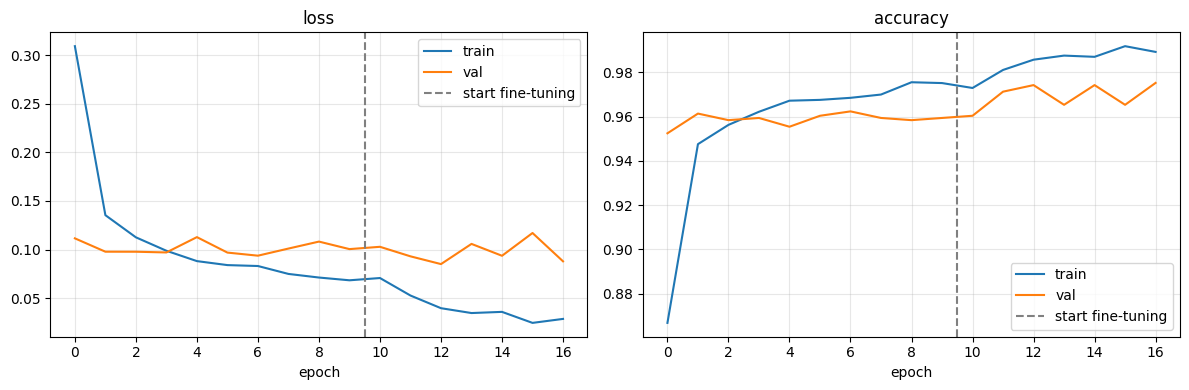

In [7]:
h = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
split = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="train"); ax[i].plot(h[f"val_{m}"], label="val")
    ax[i].axvline(split - 0.5, ls="--", c="gray", label="start fine-tuning")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

## 8) التقييم على الـ Test Set
**أهم رقم: Recall لفئة yawn.**

Test AUC (sklearn): 0.9992

              precision    recall  f1-score   support

     no_yawn     0.9768    0.9921    0.9844       636
        yawn     0.9921    0.9766    0.9843       640

    accuracy                         0.9843      1276
   macro avg     0.9844    0.9844    0.9843      1276
weighted avg     0.9844    0.9843    0.9843      1276



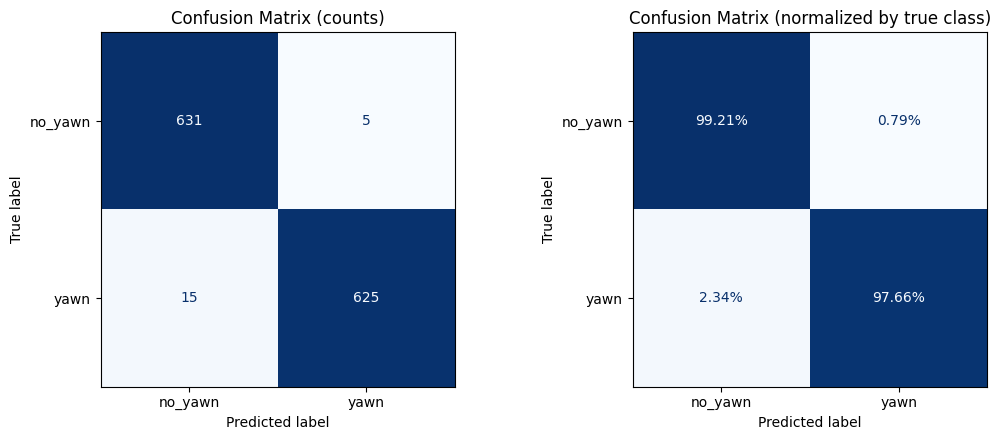

In [8]:
y_true = dfs["test"].label.values
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(f"Test AUC (sklearn): {roc_auc_score(y_true, y_prob):.4f}"); print()
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion Matrix (normalized by true class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

## 9) حفظ النموذج والنتائج

In [9]:
model.save(f"{OUT}/mouth_mobilenetv2.keras")
model.save_weights(f"{OUT}/mouth_mobilenetv2.weights.h5")
h.to_csv(f"{OUT}/history.csv", index=False)
metrics = {
    "model": "mouth_mobilenetv2_finetuned",
    "params": int(model.count_params()),
    "epochs_head": split, "epochs_finetune": len(h) - split,
    "best_val_loss": float(h.val_loss.min()),
    "test_accuracy": report["accuracy"],
    "test_auc": float(roc_auc_score(y_true, y_prob)),
    "no_yawn": {k: report["no_yawn"][k] for k in ["precision", "recall", "f1-score", "support"]},
    "yawn":    {k: report["yawn"][k]    for k in ["precision", "recall", "f1-score", "support"]},
    "confusion_matrix": cm.tolist(),
    "hyperparameters": {"img_size": IMG_SIZE, "batch": BATCH, "lr_head": LR_HEAD,
                        "lr_finetune": LR_FT, "fine_tune_at": FINE_TUNE_AT},
}
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("\nFiles:", sorted(os.listdir(OUT)))

{
  "model": "mouth_mobilenetv2_finetuned",
  "params": 2259265,
  "epochs_head": 10,
  "epochs_finetune": 7,
  "best_val_loss": 0.08504602313041687,
  "test_accuracy": 0.9843260188087775,
  "test_auc": 0.9992408608490566,
  "no_yawn": {
    "precision": 0.9767801857585139,
    "recall": 0.9921383647798742,
    "f1-score": 0.984399375975039,
    "support": 636.0
  },
  "yawn": {
    "precision": 0.9920634920634921,
    "recall": 0.9765625,
    "f1-score": 0.984251968503937,
    "support": 640.0
  },
  "confusion_matrix": [
    [
      631,
      5
    ],
    [
      15,
      625
    ]
  ],
  "hyperparameters": {
    "img_size": 96,
    "batch": 64,
    "lr_head": 0.001,
    "lr_finetune": 1e-05,
    "fine_tune_at": 100
  }
}

Files: ['best_finetune.keras', 'best_head.keras', 'confusion_matrix.png', 'history.csv', 'history_finetune.csv', 'history_head.csv', 'metrics.json', 'mouth_mobilenetv2.keras', 'mouth_mobilenetv2.weights.h5', 'training_curves.png']


## 10) مقارنة مع v2
**اختياري:** ضيفي output نوتبوك `mouth-CNN-v2` كـ Input، والخلية بتلاقي النتائج لحالها.

In [10]:
rows = []
for name in ["mouth_cnn_v2", "mouth_mobilenetv2", "mouth_cnn_tuned"]:
    f = glob.glob(f"/kaggle/input/**/{name}/metrics.json", recursive=True)
    if name == "mouth_mobilenetv2":
        m = metrics
    elif f:
        m = json.load(open(f[0]))
    else:
        continue
    rows.append({"model": m["model"], "params": m["params"], "val_loss": m["best_val_loss"],
                 "accuracy": m["test_accuracy"], "auc": m["test_auc"],
                 "yawn_recall": m["yawn"]["recall"], "yawn_precision": m["yawn"]["precision"],
                 "missed_yawns": m["confusion_matrix"][1][0], "false_alarms": m["confusion_matrix"][0][1]})
cmp = pd.DataFrame(rows).set_index("model")
cmp.to_csv(f"{OUT}/comparison.csv")
display(cmp)
if len(cmp) == 1:
    print("ℹ️ لمقارنة كاملة: ضيفي output نوتبوكات mouth-CNN-v2 (والـ mobilenet) كـ Input.")

,params,val_loss,accuracy,auc,yawn_recall,yawn_precision,missed_yawns,false_alarms
model,,,,,,,,
mouth_cnn_v2,304993,0.096972,0.985893,0.999285,0.987500,0.984424,8,10
mouth_mobilenetv2_finetuned,2259265,0.085046,0.984326,0.999241,0.976562,0.992063,15,5
